In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve, f1_score)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [21]:
FILE_PATH = 'default of credit card clients.xls'   
df = pd.read_excel(FILE_PATH, header=1)
df = df.rename(columns={'default payment next month': 'DEFAULT', 'PAY_0': 'PAY_1'})
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [22]:
df.info()
print('\nMissing values:', df.isna().sum().sum())
print('Duplicate rows (ignoring ID):', df.drop(columns='ID').duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_1      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   30000 non-nu

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Default rate: 0.2212


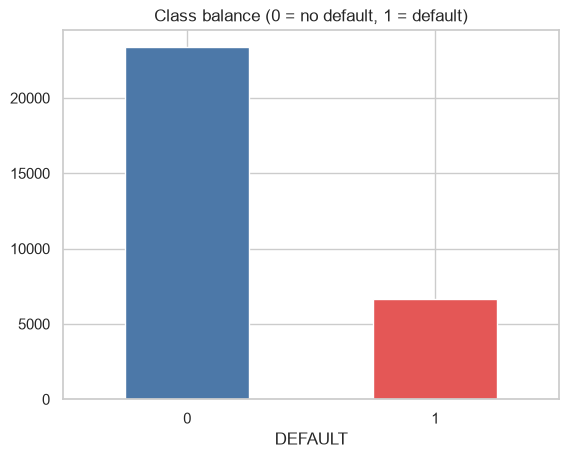

In [23]:
print(df['DEFAULT'].value_counts())
print('\nDefault rate:', round(df['DEFAULT'].mean(), 4))
df['DEFAULT'].value_counts().plot(kind='bar', color=['#4c78a8', '#e45756'])
plt.title('Class balance (0 = no default, 1 = default)'); plt.xticks(rotation=0); plt.show()

In [24]:
df = df.drop(columns='ID').drop_duplicates().reset_index(drop=True)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})
print(df.shape)
print(df['EDUCATION'].value_counts().sort_index())
print(df['MARRIAGE'].value_counts().sort_index())

(29965, 24)
EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64
MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


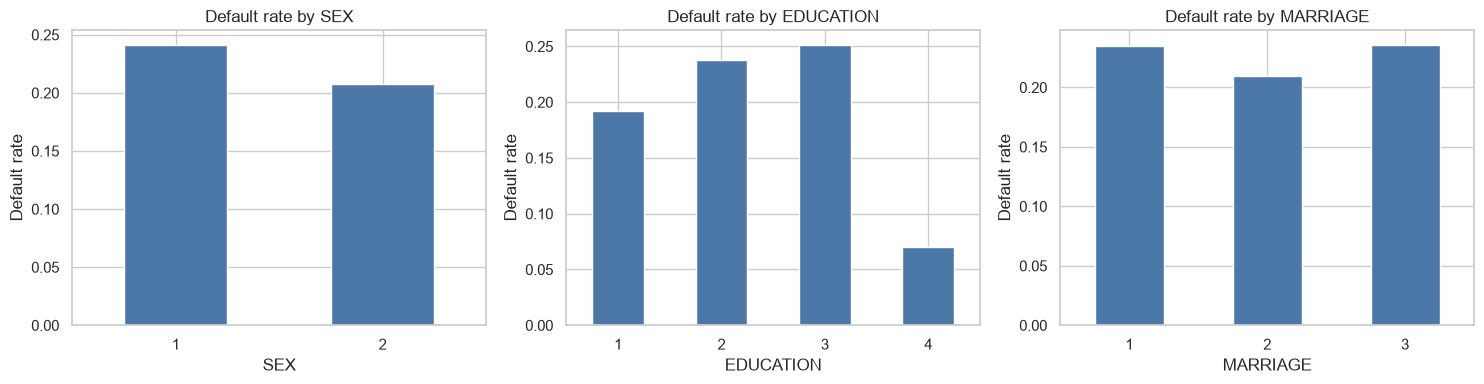

In [25]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['SEX', 'EDUCATION', 'MARRIAGE']):
    df.groupby(col)['DEFAULT'].mean().plot(kind='bar', ax=ax, color='#4c78a8')
    ax.set_title(f'Default rate by {col}'); ax.set_ylabel('Default rate'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

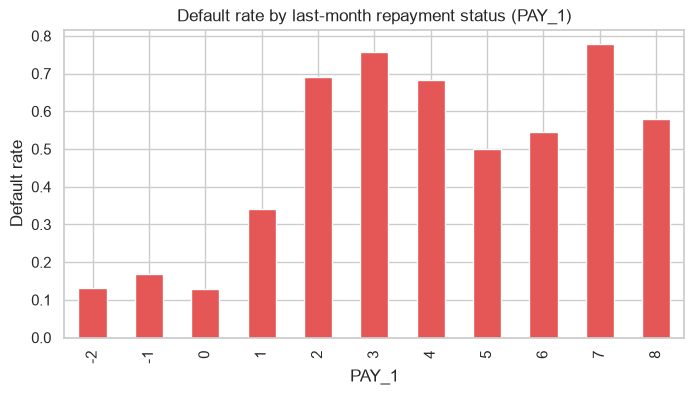

In [26]:
# Default rate by repayment status (strongest signal)
df.groupby('PAY_1')['DEFAULT'].mean().plot(kind='bar', figsize=(8, 4), color='#e45756')
plt.title('Default rate by last-month repayment status (PAY_1)'); plt.ylabel('Default rate'); plt.show()

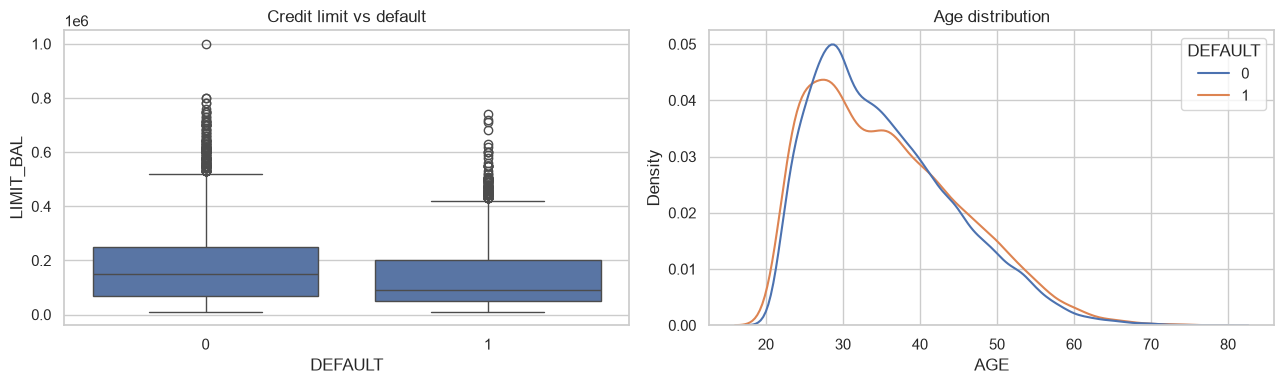

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='DEFAULT', y='LIMIT_BAL', ax=axes[0]); axes[0].set_title('Credit limit vs default')
sns.kdeplot(data=df, x='AGE', hue='DEFAULT', common_norm=False, ax=axes[1]); axes[1].set_title('Age distribution')
plt.tight_layout(); plt.show()

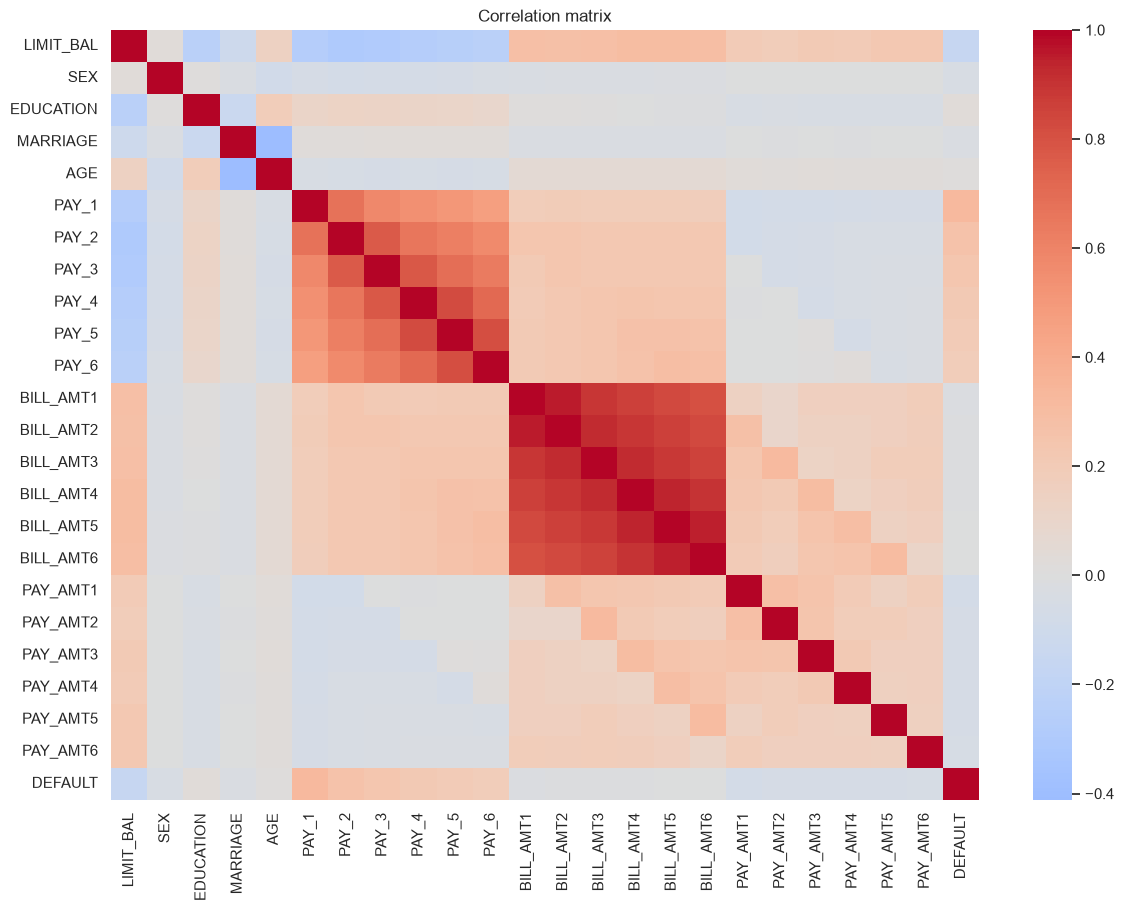

PAY_1        0.324964
PAY_2        0.263656
PAY_3        0.235230
PAY_4        0.216551
PAY_5        0.204059
PAY_6        0.186740
EDUCATION    0.033862
AGE          0.013619
BILL_AMT6   -0.005469
BILL_AMT5   -0.006859
BILL_AMT4   -0.010259
BILL_AMT3   -0.014182
BILL_AMT2   -0.014302
BILL_AMT1   -0.019758
MARRIAGE    -0.027259
SEX         -0.039742
PAY_AMT6    -0.053250
PAY_AMT5    -0.055194
PAY_AMT3    -0.056319
PAY_AMT4    -0.056898
PAY_AMT2    -0.058643
PAY_AMT1    -0.073015
LIMIT_BAL   -0.153871
Name: DEFAULT, dtype: float64

In [28]:
# Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix'); plt.show()
df.corr()['DEFAULT'].drop('DEFAULT').sort_values(ascending=False)

In [29]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
pay_cols  = [f'PAY_AMT{i}' for i in range(1, 7)]
status_cols = ['PAY_1'] + [f'PAY_{i}' for i in range(2, 7)]

df['AVG_BILL'] = df[bill_cols].mean(axis=1)
df['AVG_PAY_AMT'] = df[pay_cols].mean(axis=1)
df['PAY_RATIO'] = df[pay_cols].sum(axis=1) / (df[bill_cols].clip(lower=0).sum(axis=1) + 1)
df['UTILIZATION'] = df['BILL_AMT1'] / df['LIMIT_BAL']
df['MAX_DELAY'] = df[status_cols].max(axis=1)
df['MONTHS_DELAYED'] = (df[status_cols] > 0).sum(axis=1)
df[['AVG_BILL', 'AVG_PAY_AMT', 'PAY_RATIO', 'UTILIZATION', 'MAX_DELAY', 'MONTHS_DELAYED']].describe().T

,count,mean,std,min,25%,50%,75%,max
AVG_BILL,29965.0,45029.328116,63279.074163,-56043.166667,4841.000000,21110.833333,57166.166667,877313.833333
AVG_PAY_AMT,29965.0,5281.297308,10142.306855,0.000000,1116.666667,2400.000000,5600.000000,627344.333333
PAY_RATIO,29965.0,28.406524,1416.274930,0.000000,0.041337,0.088186,0.610616,162000.000000
UTILIZATION,29965.0,0.424263,0.411451,-0.619892,0.022300,0.315278,0.830325,6.455300
MAX_DELAY,29965.0,0.439146,1.344934,-2.000000,0.000000,0.000000,2.000000,8.000000
MONTHS_DELAYED,29965.0,0.834273,1.554821,0.000000,0.000000,0.000000,1.000000,6.000000


In [30]:
X = df.drop(columns='DEFAULT')
y = df['DEFAULT']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print('Train default rate:', y_train.mean().round(4), '| Test default rate:', y_test.mean().round(4))

(23972, 29) (5993, 29)
Train default rate: 0.2213 | Test default rate: 0.2213


In [31]:
models = {
    'Logistic Regression': Pipeline([('scale', StandardScaler()),
                                     ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'{name:22s} CV ROC-AUC: {scores.mean():.4f} (+/- {scores.std():.4f})')
    m.fit(X_train, y_train)

Logistic Regression    CV ROC-AUC: 0.7580 (+/- 0.0105)
Random Forest          CV ROC-AUC: 0.7823 (+/- 0.0085)
Gradient Boosting      CV ROC-AUC: 0.7869 (+/- 0.0080)


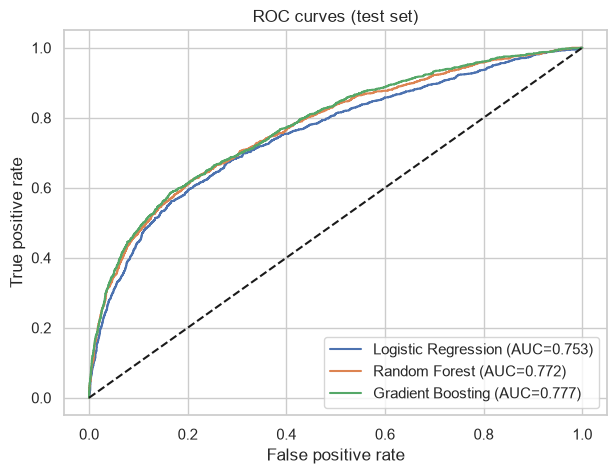

,ROC-AUC,Best threshold,F1 (default)
Model,,,
Logistic Regression,0.7528,0.5695,0.5230
Random Forest,0.7717,0.5218,0.5325
Gradient Boosting,0.7771,0.2636,0.5406


In [32]:
results = []
plt.figure(figsize=(7, 5))
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    p, r, t = precision_recall_curve(y_test, proba)
    f1 = 2 * p * r / (p + r + 1e-9)
    best_t = t[np.argmax(f1[:-1])]
    pred = (proba >= best_t).astype(int)
    results.append({'Model': name, 'ROC-AUC': roc_auc_score(y_test, proba),
                    'Best threshold': best_t, 'F1 (default)': f1_score(y_test, pred)})
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[-1]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves (test set)'); plt.legend(); plt.show()
pd.DataFrame(results).set_index('Model').round(4)

Best model: Gradient Boosting | threshold: 0.264
              precision    recall  f1-score   support

  No default       0.88      0.84      0.86      4667
     Default       0.50      0.59      0.54      1326

    accuracy                           0.78      5993
   macro avg       0.69      0.71      0.70      5993
weighted avg       0.79      0.78      0.79      5993



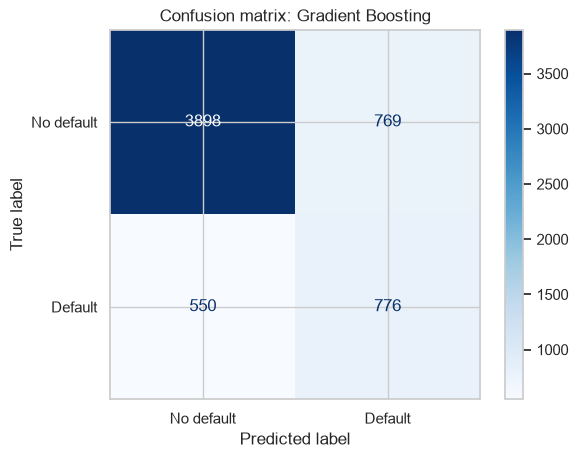

In [16]:

best_name = max(results, key=lambda r: r['ROC-AUC'])['Model']
best_model = models[best_name]
best_t = [r for r in results if r['Model'] == best_name][0]['Best threshold']
pred = (best_model.predict_proba(X_test)[:, 1] >= best_t).astype(int)
print('Best model:', best_name, '| threshold:', round(best_t, 3))
print(classification_report(y_test, pred, target_names=['No default', 'Default']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['No default', 'Default']).plot(cmap='Blues')
plt.title(f'Confusion matrix: {best_name}'); plt.show()

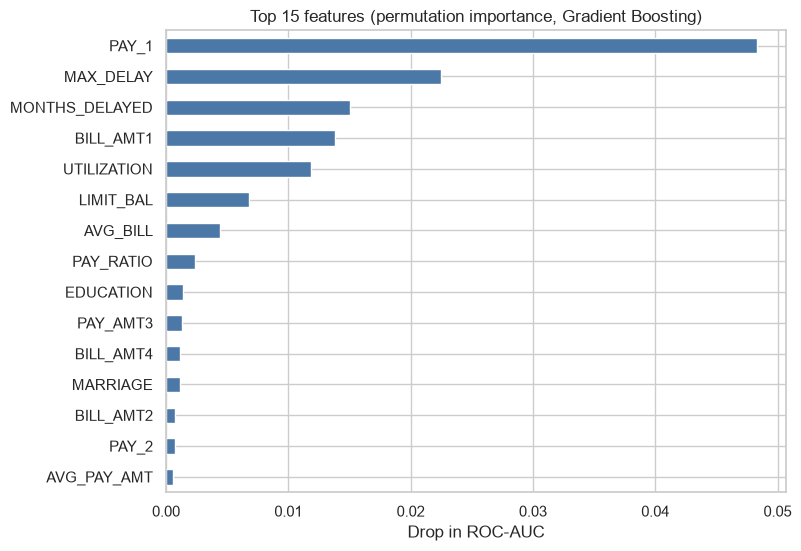

In [17]:
imp = permutation_importance(best_model, X_test, y_test, scoring='roc_auc',
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
imp_df.head(15).iloc[::-1].plot(kind='barh', figsize=(8, 6), color='#4c78a8')
plt.title(f'Top 15 features (permutation importance, {best_name})'); plt.xlabel('Drop in ROC-AUC'); plt.show()

In [35]:
import joblib
joblib.dump(best_model, 'credit_default_model.joblib')

['credit_default_model.joblib']